In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mpl_toolkits.axes_grid1 import make_axes_locatable
import pandas as pd
from scipy.optimize import curve_fit


import tifffile as tiff

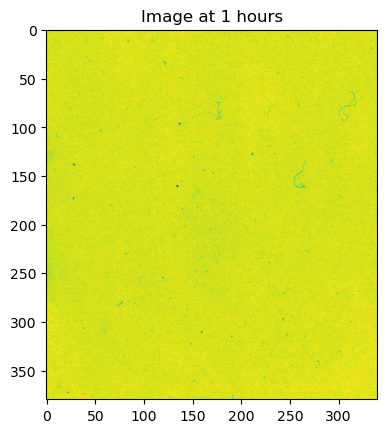

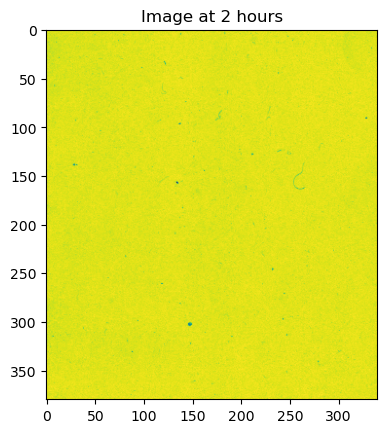

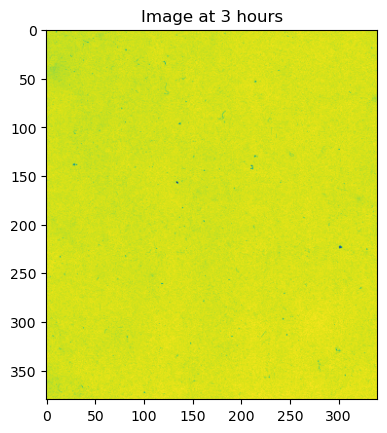

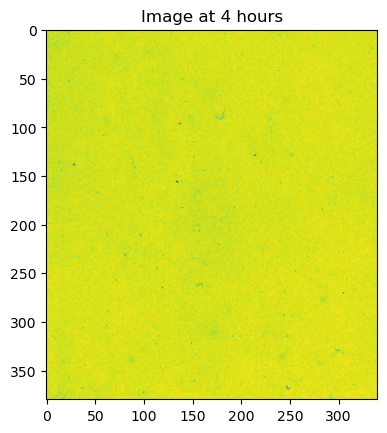

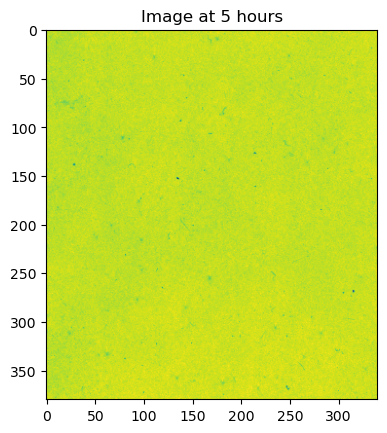

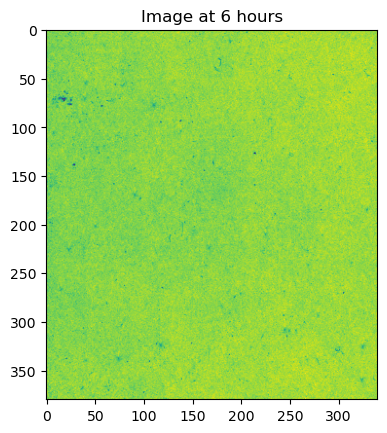

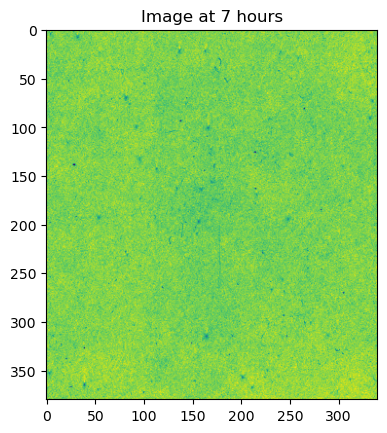

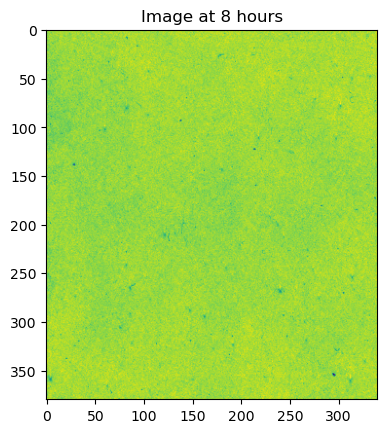

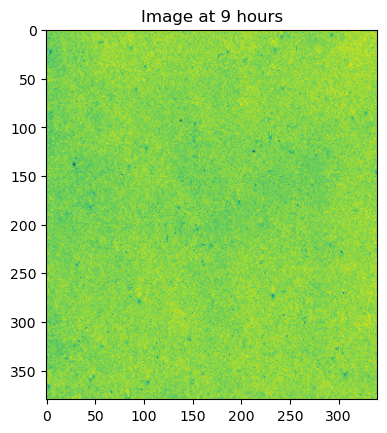

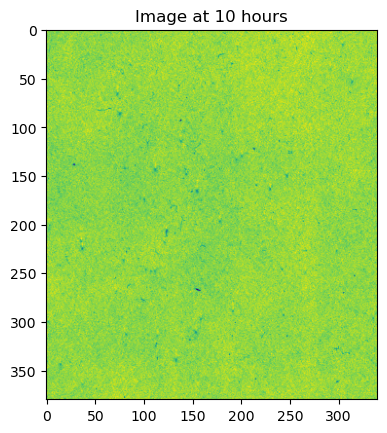

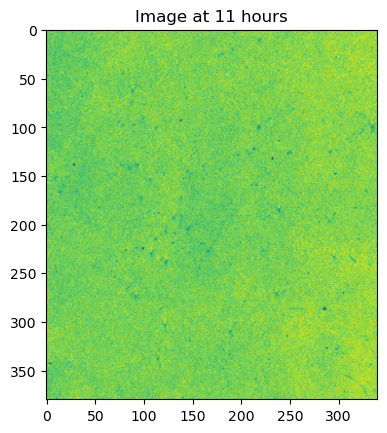

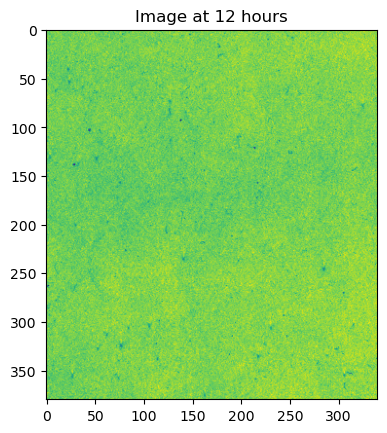

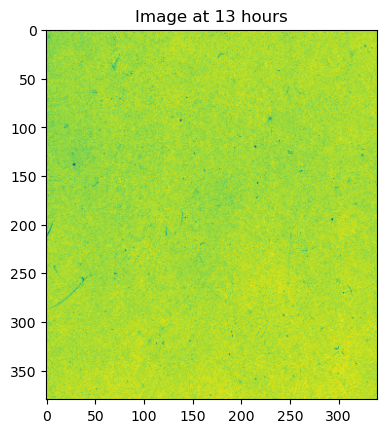

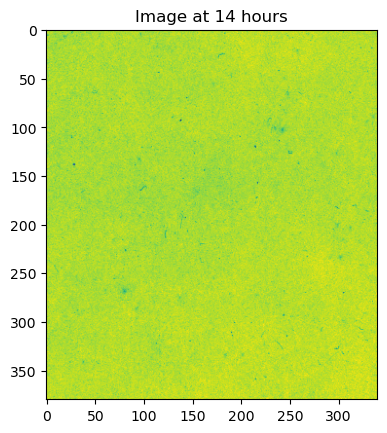

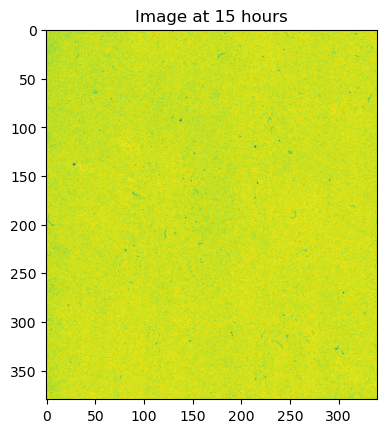

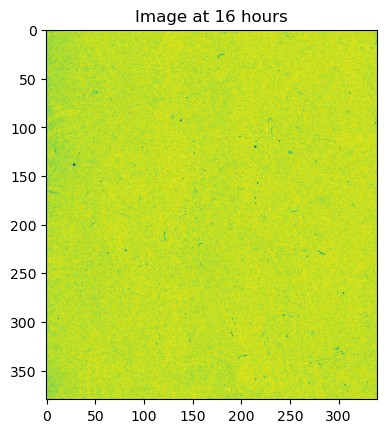

In [ ]:
for i in range(1, 17):
    if i < 10:
        img = tiff.imread(f"CLEAR_dosimetry/FilmDosimetryGUI_macOS/Calibration_03032503_21h/A_00{i}.tif")[50:430,30:370,:]
    else:
        img = tiff.imread(f"CLEAR_dosimetry/FilmDosimetryGUI_macOS/Calibration_03032503_21h/A_0{i}.tif")[50:430,30:370,:] 

    
    channel = 0
    plt.imshow(img[:,:,channel])
    plt.title(f"Image at {i} hours")
    plt.show()


In [7]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import tifffile as tiff

# Folder containing A_001.tif ... A_016.tif
img_dir = Path("CLEAR_RCF/21h")

# Map film label to delivered dose (Gy)
# Fill in any missing labels if needed.
import numpy as np
import tifffile as tiff
import pandas as pd

dose_by_film = {
    "A01": 0.10009, "A02": 0.10009,
    "A03": 0.99988, "A04": 0.99988,
    "A05": 6.00025, "A06": 6.00025,
    "A07": 8.99989, "A08": 8.99989,
    "A09": 11.9995, "A10": 11.9995,
    "A11": 19.9995, "A12": 19.9995,
    "A13": 2.99964, "A14": 2.99964,
    "A15": 0, "A16": 0
}

films_df = pd.DataFrame({
    "film": list(dose_by_film.keys()),
    "dose_Gy": list(dose_by_film.values())
})

# Lists to store results
pv_red = []
pv_green = []
pv_blue = []

for i in range(1, 17):
    if i < 10:
        path = f"CLEAR_dosimetry/FilmDosimetryGUI_macOS/Calibration_03032503_21h/A_00{i}.tif"
    else:
        path = f"CLEAR_dosimetry/FilmDosimetryGUI_macOS/Calibration_03032503_21h/A_0{i}.tif"

    img = tiff.imread(path)[50:430, 30:370, :]

    # Compute mean per channel
    pv_red.append(np.median(img[:, :, 0]))
    pv_green.append(np.median(img[:, :, 1]))
    pv_blue.append(np.median(img[:, :, 2]))

# Add to dataframe
films_df["PV_red"] = pv_red
films_df["PV_green"] = pv_green
films_df["PV_blue"] = pv_blue

print(films_df)

   film   dose_Gy   PV_red  PV_green  PV_blue
0   A01   0.10009  45875.0   43222.0  31328.0
1   A02   0.10009  45660.0   43010.0  31104.0
2   A03   0.99988  39128.0   38812.0  30279.0
3   A04   0.99988  39096.0   38786.0  30227.0
4   A05   6.00025  24184.0   25537.0  25998.0
5   A06   6.00025  24150.0   25486.0  25865.0
6   A07   8.99989  20832.0   21647.0  24423.0
7   A08   8.99989  20546.0   21201.0  23785.5
8   A09  11.99950  18213.0   18375.0  22289.0
9   A10  11.99950  18251.0   18489.0  22365.0
10  A11  19.99950  14669.0   13641.0  19134.0
11  A12  19.99950  14724.0   13718.0  19243.0
12  A13   2.99964  31062.0   32247.0  28415.0
13  A14   2.99964  31071.0   32307.0  28543.0
14  A15   0.00000  46788.0   43717.0  31027.0
15  A16   0.00000  46655.0   43561.0  30892.0


In [8]:
# --- Make sure these columns exist ---
for ch in ["red", "green", "blue"]:
    films_df[f"OD_{ch}"] = -np.log(films_df[f"PV_{ch}"] / 65535)

background = films_df[films_df["film"].isin(["A15", "A16"])]

OD0 = {
    ch: background[f"OD_{ch}"].mean()
    for ch in ["red", "green", "blue"]
}

for ch in ["red", "green", "blue"]:
    films_df[f"nOD_{ch}"] = films_df[f"OD_{ch}"] - OD0[ch]

print(films_df.columns)  # optional check


Index(['film', 'dose_Gy', 'PV_red', 'PV_green', 'PV_blue', 'OD_red',
       'OD_green', 'OD_blue', 'nOD_red', 'nOD_green', 'nOD_blue'],
      dtype='str')


red: a=4.5211, b=0.1609, c=4.5522
   chi2 = 0.0004, reduced chi2 = 0.0000
green: a=7.9284, b=0.0414, c=7.9364
   chi2 = 0.0004, reduced chi2 = 0.0000
blue: a=24.0703, b=0.1513, c=23.7625
   chi2 = 0.0005, reduced chi2 = 0.0000


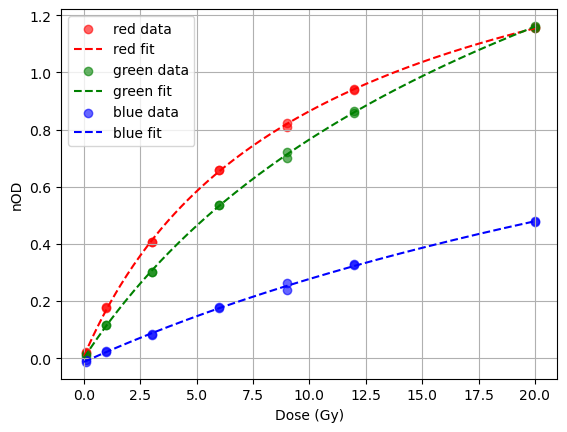

In [9]:
# --- Model ---
def nOD_model(D, a, b, c):
    return -np.log((a + b * D) / (c + D))

fit_params = {}
chi2_results = {}

D_plot = np.linspace(0, max(films_df["dose_Gy"]), 200)

plt.figure()

for ch, color in zip(["red", "green", "blue"], ["r", "g", "b"]):

    # Data (exclude zero dose)
    fit_df = films_df[films_df["dose_Gy"] > 0]
    D = fit_df["dose_Gy"].values
    y = fit_df[f"nOD_{ch}"].values

    # Fit
    p0 = [1, 0.1, 1]
    popt, pcov = curve_fit(nOD_model, D, y, p0=p0, maxfev=10000)

    fit_params[ch] = popt

    # --- Chi-squared ---
    y_fit = nOD_model(D, *popt)

    # If you don't have uncertainties, assume equal weights → σ = 1
    residuals = y - y_fit
    chi2 = np.sum((residuals)**2)

    # Reduced chi² (more useful)
    dof = len(y) - len(popt)
    chi2_red = chi2 / dof

    chi2_results[ch] = (chi2, chi2_red)

    print(f"{ch}: a={popt[0]:.4f}, b={popt[1]:.4f}, c={popt[2]:.4f}")
    print(f"   chi2 = {chi2:.4f}, reduced chi2 = {chi2_red:.4f}")

    # --- Plot ---
    plt.scatter(D, y, color=color, label=f"{ch} data",alpha=0.6)
    plt.plot(D_plot, nOD_model(D_plot, *popt), color=color, linestyle="--", label=f"{ch} fit")

plt.xlabel("Dose (Gy)")
plt.ylabel("nOD")
plt.legend()
plt.grid()
plt.show()


red (inverted fit): a=4.6093, b=0.1574, c=4.6606
   chi2 = 0.1076, reduced chi2 = 0.0098
green (inverted fit): a=7.9162, b=0.0418, c=7.9213
   chi2 = 0.1161, reduced chi2 = 0.0106
blue (inverted fit): a=23.5294, b=0.1614, c=23.2037
   chi2 = 0.8150, reduced chi2 = 0.0741


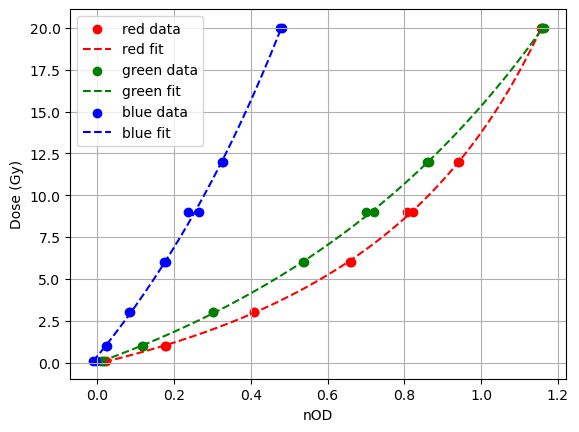

In [10]:

# --- Inverted model ---
def D_model(nOD, a, b, c):
    exp_term = np.exp(-nOD)
    return (a - c * exp_term) / (exp_term - b)

fit_params_inv = {}
chi2_results_inv = {}

plt.figure()

for ch, color in zip(["red", "green", "blue"], ["r", "g", "b"]):

    # Use only non-zero dose
    fit_df = films_df[films_df["dose_Gy"] > 0]

    x = fit_df[f"nOD_{ch}"].values   # nOD
    y = fit_df["dose_Gy"].values     # Dose

    # --- Initial guess (IMPORTANT here)
    p0 = [1, 0.01, 1]

    popt, pcov = curve_fit(D_model, x, y, p0=p0, maxfev=20000)

    fit_params_inv[ch] = popt

    # --- Chi-squared ---
    y_fit = D_model(x, *popt)
    residuals = y - y_fit

    chi2 = np.sum(residuals**2)
    dof = len(y) - len(popt)
    chi2_red = chi2 / dof

    chi2_results_inv[ch] = (chi2, chi2_red)

    print(f"{ch} (inverted fit): a={popt[0]:.4f}, b={popt[1]:.4f}, c={popt[2]:.4f}")
    print(f"   chi2 = {chi2:.4f}, reduced chi2 = {chi2_red:.4f}")

    # --- Plot ---
    x_plot = np.linspace(min(x), max(x), 200)
    plt.scatter(x, y, color=color, label=f"{ch} data")
    plt.plot(x_plot, D_model(x_plot, *popt), color=color, linestyle="--", label=f"{ch} fit")

plt.xlabel("nOD")
plt.ylabel("Dose (Gy)")
plt.legend()
plt.grid()
plt.show()

red polynomial coefficients (p4 → p0):
[ 9.56465954e+00 -1.00096134e+01  1.01602326e+01  4.12083547e+00
  7.26233391e-03]
   chi2 = 0.096332, reduced chi2 = 0.010704
green polynomial coefficients (p4 → p0):
[ 1.46014808  0.98750624  4.57336183  8.33547864 -0.01277002]
   chi2 = 0.115504, reduced chi2 = 0.012834
blue polynomial coefficients (p4 → p0):
[129.62111299 -72.99599522  30.51809185  28.99559952   0.33870407]
   chi2 = 0.740384, reduced chi2 = 0.082265


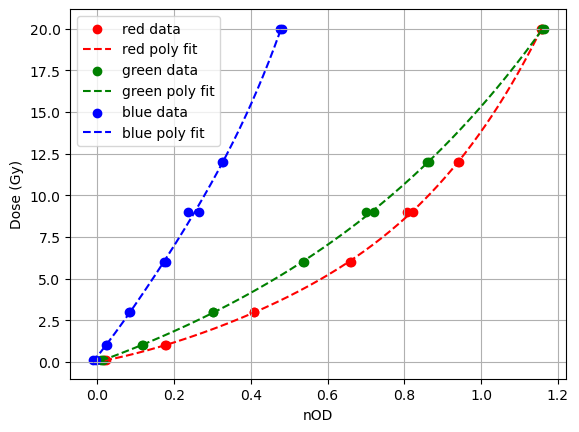

In [ ]:
#polynomial fit (degree 4) for comparison
poly_coeffs = {}
chi2_results_poly = {}

plt.figure()

for ch, color in zip(["red", "green", "blue"], ["r", "g", "b"]):

    # Use non-zero dose points
    fit_df = films_df[films_df["dose_Gy"] > 0]

    x = fit_df[f"nOD_{ch}"].values   # nOD
    y = fit_df["dose_Gy"].values     # Dose

    # --- Fit polynomial (degree 4) ---
    coeffs = np.polyfit(x, y, 4)  # returns [p4, p3, p2, p1, p0]
    poly = np.poly1d(coeffs)

    poly_coeffs[ch] = coeffs

    # --- Chi-squared ---
    y_fit = poly(x)
    residuals = y - y_fit

    chi2 = np.sum(residuals**2)
    dof = len(y) - 5  # 5 parameters
    chi2_red = chi2 / dof

    chi2_results_poly[ch] = (chi2, chi2_red)

    print(f"{ch} polynomial coefficients (p4 → p0):")
    print(coeffs)
    print(f"   chi2 = {chi2:.6f}, reduced chi2 = {chi2_red:.6f}")

    # --- Plot ---
    x_plot = np.linspace(x.min(), x.max(), 200)
    plt.scatter(x, y, color=color, label=f"{ch} data")
    plt.plot(x_plot, poly(x_plot), color=color, linestyle="--", label=f"{ch} poly fit")

plt.xlabel("nOD")
plt.ylabel("Dose (Gy)")
plt.legend()
plt.grid(True)
plt.show()